In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('DailyDelhiClimateTest.csv')

In [5]:
df = df[['date', 'meantemp']]
df

,date,meantemp
0,2017-01-01,15.913043
1,2017-01-02,18.500000
2,2017-01-03,17.111111
3,2017-01-04,18.700000
4,2017-01-05,18.388889
...,...,...
109,2017-04-20,34.500000
110,2017-04-21,34.250000
111,2017-04-22,32.900000
112,2017-04-23,32.875000


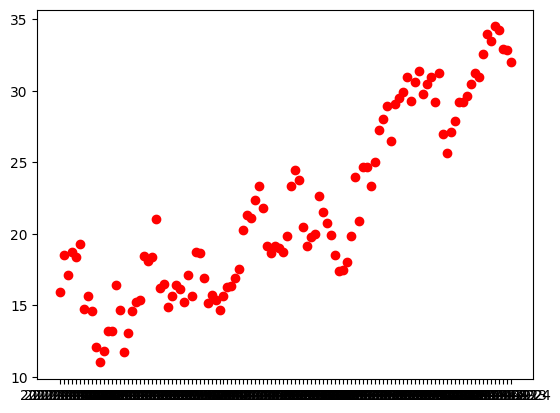

In [6]:
plt.scatter(df['date'], df['meantemp'], color = 'red')

In [7]:
# Apply the formula
#x1 = df['meantemp'].ewm(alpha = 0.9).mean()

In [16]:
# Manual coding
x1 = [df['meantemp'][0]]
alpha = 0.9

for i in range(1, len(df['meantemp'])):
    ewma_t = alpha * df['meantemp'][i] + (1 - alpha) * x1[-1]
    x1.append(ewma_t)
x1 = pd.Series(x1)
x1

,0
0,15.913043
1,18.241304
2,17.224130
3,18.552413
4,18.405241
...,...
109,34.403401
110,34.265340
111,33.036534
112,32.891153


In [17]:
df['ewma'] = x1
df

/tmp/ipython-input-1474798532.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ewma'] = x1


,date,meantemp,ewma
0,2017-01-01,15.913043,15.913043
1,2017-01-02,18.500000,18.241304
2,2017-01-03,17.111111,17.224130
3,2017-01-04,18.700000,18.552413
4,2017-01-05,18.388889,18.405241
...,...,...,...
109,2017-04-20,34.500000,34.403401
110,2017-04-21,34.250000,34.265340
111,2017-04-22,32.900000,33.036534
112,2017-04-23,32.875000,32.891153


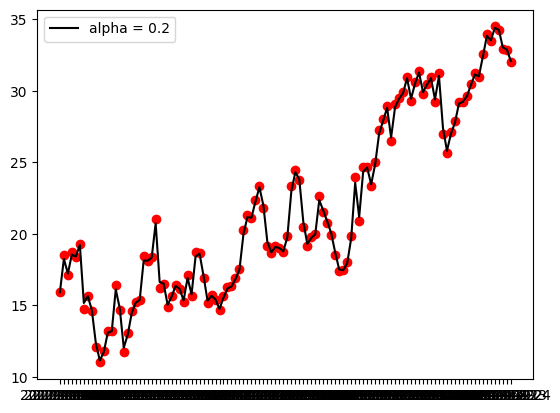

In [18]:
plt.scatter(df['date'], df['meantemp'], color = 'red')
plt.plot(df['date'], x1,color = 'black', label = 'alpha = 0.2')
plt.legend()
plt.show()